# Graph-search results

This is the common notebook for graph-search experiments. It combines the human-qrel performance comparison, the baseline-versus-expanded-budget ablation, and an interactive browser for individual search traces and decision trees.

Path-aware and feature-collapsed catalog views remain separate candidate universes throughout. The tree shows each retained bounded-search branch; the green edge is that decision's top-ranked action, while gray edges are additional actions retained by the branch width. Action probabilities or utilities are local to their decision menu and are not comparable across graph states.


In [1]:
from pathlib import Path
import json
import os
import sys

import pandas as pd
from IPython.display import Markdown, clear_output, display

try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

MPL_CONFIG = Path('/tmp/simbench-matplotlib')
MPL_CONFIG.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(MPL_CONFIG))
import matplotlib.pyplot as plt

REPO = Path('/storage/lcostes/Similarity_benchmark')
sys.path.insert(0, str(REPO))
from src.evaluation.ranking_metrics import ranking_metrics

SUITES = ('v1', 'v2', 'v3')
BASELINE_BUDGET = (30, 3, 10)
EXPANDED_BUDGET = (60, 4, 20)

def read_jsonl(path):
    with Path(path).open(encoding='utf-8') as stream:
        return [json.loads(line) for line in stream if line.strip()]

def human_qrels(path, catalog_view):
    grades = {}
    for row in read_jsonl(path):
        candidate = row.get('candidate')
        direct_attribute = (
            isinstance(candidate, dict)
            and candidate.get('kind') == 'attribute'
            and len(candidate.get('path', [])) == 1
        )
        if catalog_view == 'feature-collapsed' and not direct_attribute:
            continue
        if row.get('status') not in {'judged', 'complete'} or type(row.get('grade')) is not int:
            continue
        grades.setdefault(row['condition_id'], {})[row['candidate_id']] = row['grade']
    return grades

run_rows = []
trace_runs = []
for suite in SUITES:
    result_dir = REPO / f'results/rel-amazon/discovery/condition-{suite}-catalog-views'
    qrel_path = REPO / f'annotations/rel-amazon/human/conditions-{suite}/lysandre.jsonl'
    if not result_dir.exists() or not qrel_path.exists():
        continue
    for result_path in sorted(result_dir.glob('graph*.jsonl')):
        for run in read_jsonl(result_path):
            if run.get('method') not in {'graph-search', 'graph-search-oracle-root'}:
                continue
            graph = run.get('graph_search')
            config = run.get('graph_search_config') or {}
            if not isinstance(graph, dict):
                continue
            catalog = run.get('signal_catalog', 'path-aware')
            qrels = human_qrels(qrel_path, catalog).get(run.get('condition_id'), {})
            ranked = [signal.get('id') for signal in run.get('signals', []) if isinstance(signal, dict) and signal.get('id') in qrels]
            budget = (config.get('max_decisions'), config.get('branch_width'), config.get('max_signals'))
            label = f"{suite} | {run.get('method')} | {run.get('model')} | {catalog} | d{budget[0]}/w{budget[1]}/s{budget[2]}"
            trace_runs.append({'label': label, 'suite': suite, 'file': result_path, 'run': run})
            if qrels:
                run_rows.append({
                    'suite': suite, 'condition_id': run.get('condition_id'), 'condition': run.get('condition'),
                    'method': run.get('method'), 'model': run.get('model'), 'catalog': catalog,
                    'budget': budget, 'decisions': budget[0], 'branch width': budget[1], 'max signals': budget[2],
                    'returned signals': len(run.get('signals', [])),
                    'top-5 human grades': [qrels.get(signal.get('id')) for signal in run.get('signals', [])[:5] if isinstance(signal, dict)],
                    **ranking_metrics(ranked, qrels),
                })

graph_metrics = pd.DataFrame(run_rows)
if graph_metrics.empty:
    raise FileNotFoundError('No graph-search results with matching human qrels were found.')
print(f'Loaded {len(graph_metrics)} condition-level rankings from {len({item["file"] for item in trace_runs})} graph-search files.')
print('Budgets found:', sorted(set(graph_metrics['budget'])))


Loaded 360 condition-level rankings from 72 graph-search files.
Budgets found: [(30, 3, 10), (60, 4, 20)]


## Overall human-qrel comparison

Scores are macro-averaged across the available conditions in each suite. Bars are deliberately split by catalog view rather than treating path-aware and feature-collapsed rankings as directly comparable.


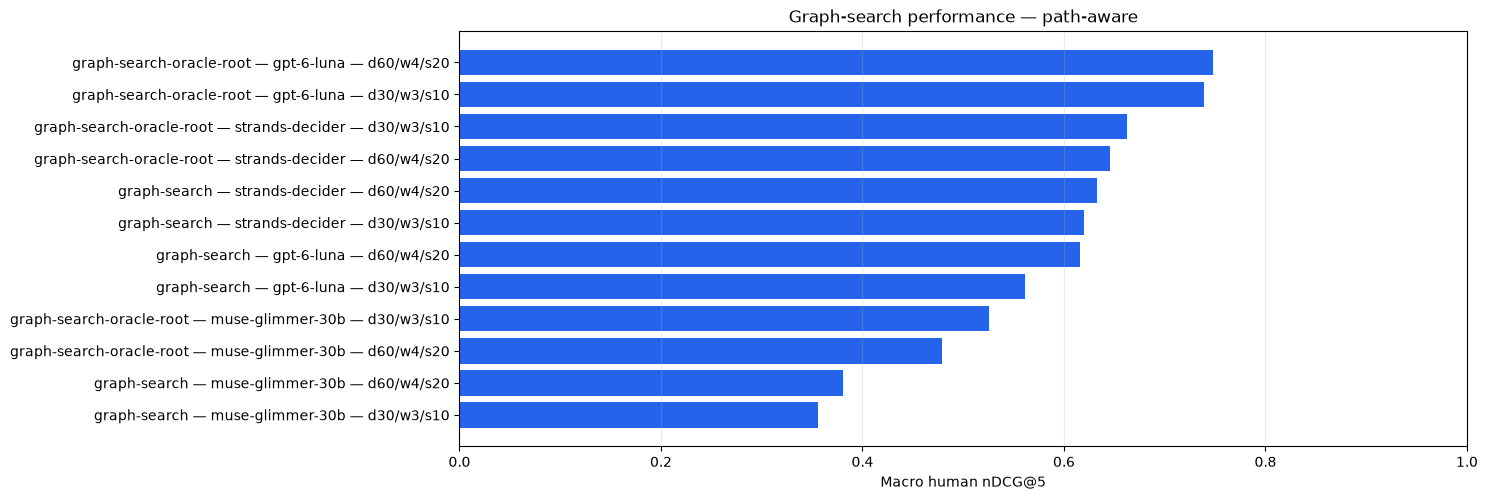

,method,model,decisions,branch width,max signals,ndcg@1,ndcg@3,ndcg@5,ndcg@10
19,graph-search-oracle-root,gpt-6-luna,60,4,20,0.886,0.795,0.748,0.676
18,graph-search-oracle-root,gpt-6-luna,30,3,10,0.848,0.784,0.739,0.650
22,graph-search-oracle-root,strands-decider,30,3,10,0.771,0.715,0.662,0.638
23,graph-search-oracle-root,strands-decider,60,4,20,0.705,0.697,0.646,0.616
17,graph-search,strands-decider,60,4,20,0.683,0.621,0.633,0.616
16,graph-search,strands-decider,30,3,10,0.606,0.666,0.620,0.579
13,graph-search,gpt-6-luna,60,4,20,0.714,0.641,0.616,0.546
12,graph-search,gpt-6-luna,30,3,10,0.632,0.592,0.562,0.483
20,graph-search-oracle-root,muse-glimmer-30b,30,3,10,0.667,0.521,0.525,0.524
21,graph-search-oracle-root,muse-glimmer-30b,60,4,20,0.610,0.484,0.479,0.513


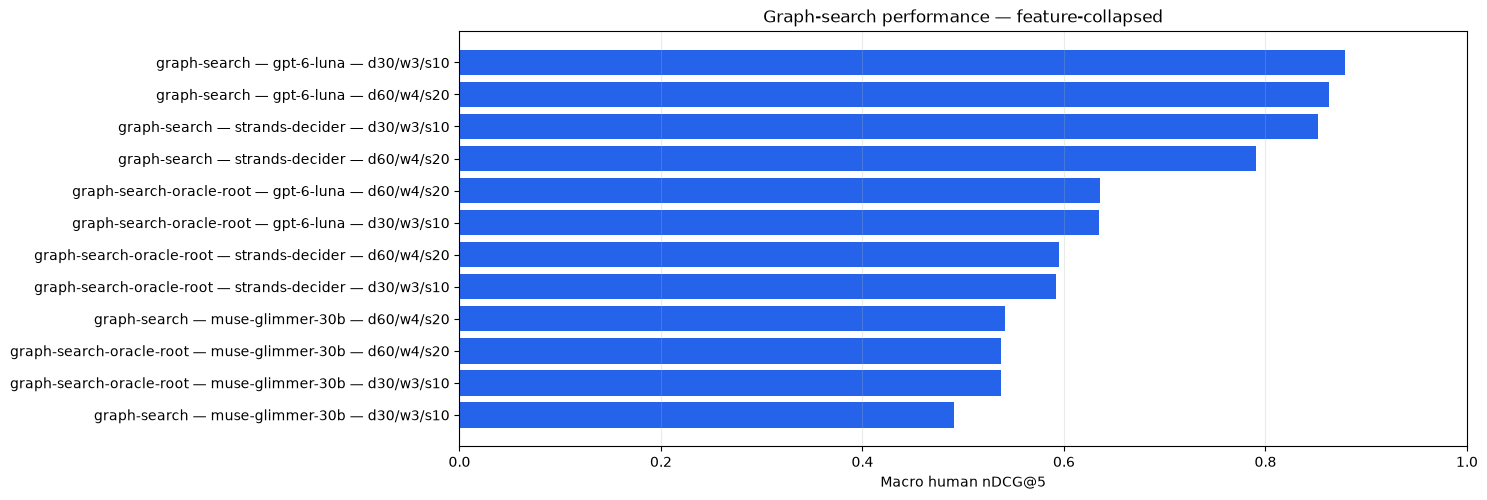

,method,model,decisions,branch width,max signals,ndcg@1,ndcg@3,ndcg@5,ndcg@10
0,graph-search,gpt-6-luna,30,3,10,1.000,0.928,0.879,0.857
1,graph-search,gpt-6-luna,60,4,20,0.911,0.884,0.863,0.838
4,graph-search,strands-decider,30,3,10,0.705,0.854,0.852,0.893
5,graph-search,strands-decider,60,4,20,0.651,0.783,0.791,0.823
7,graph-search-oracle-root,gpt-6-luna,60,4,20,0.733,0.666,0.636,0.603
6,graph-search-oracle-root,gpt-6-luna,30,3,10,0.733,0.661,0.635,0.602
11,graph-search-oracle-root,strands-decider,60,4,20,0.571,0.607,0.595,0.565
10,graph-search-oracle-root,strands-decider,30,3,10,0.571,0.596,0.592,0.564
3,graph-search,muse-glimmer-30b,60,4,20,0.441,0.464,0.542,0.524
8,graph-search-oracle-root,muse-glimmer-30b,30,3,10,0.476,0.444,0.538,0.513


In [2]:
metric_columns = ['ndcg@1', 'ndcg@3', 'ndcg@5', 'ndcg@10']
overall_keys = ['catalog', 'method', 'model', 'budget', 'decisions', 'branch width', 'max signals']
overall = graph_metrics.groupby(overall_keys, as_index=False)[metric_columns].mean()

for catalog in ('path-aware', 'feature-collapsed'):
    view = overall[overall['catalog'].eq(catalog)].copy()
    if view.empty:
        continue
    view['run'] = view.apply(lambda row: f"{row['method']} — {row['model']} — d{row['decisions']}/w{row['branch width']}/s{row['max signals']}", axis=1)
    view = view.sort_values('ndcg@5')
    fig, ax = plt.subplots(figsize=(13, max(4, 0.45 * len(view))))
    ax.barh(view['run'], view['ndcg@5'], color='#2563eb')
    ax.set_xlim(0, 1)
    ax.set_xlabel('Macro human nDCG@5')
    ax.set_title(f'Graph-search performance — {catalog}')
    ax.grid(axis='x', alpha=0.25)
    plt.show()
    display(view[['method', 'model', 'decisions', 'branch width', 'max signals', *metric_columns]].sort_values('ndcg@5', ascending=False).round(3))


## Graph-search budget ablation

The delta is expanded budget minus baseline budget. Positive values mean that expanding the search from `(30 decisions, width 3, 10 signals)` to `(60, 4, 20)` improved macro human nDCG.


,method,model,catalog,ndcg@1 baseline,ndcg@3 baseline,ndcg@5 baseline,ndcg@10 baseline,ndcg@1 expanded,ndcg@3 expanded,ndcg@5 expanded,ndcg@10 expanded,ndcg@1 change,ndcg@3 change,ndcg@5 change,ndcg@10 change
1,graph-search,muse-glimmer-30b,feature-collapsed,0.432,0.432,0.490,0.478,0.441,0.464,0.542,0.524,0.010,0.032,0.051,0.047
5,graph-search-oracle-root,strands-decider,feature-collapsed,0.571,0.596,0.592,0.564,0.571,0.607,0.595,0.565,0.000,0.011,0.002,0.002
3,graph-search-oracle-root,gpt-6-luna,feature-collapsed,0.733,0.661,0.635,0.602,0.733,0.666,0.636,0.603,0.000,0.005,0.001,0.001
4,graph-search-oracle-root,muse-glimmer-30b,feature-collapsed,0.476,0.444,0.538,0.513,0.476,0.444,0.538,0.513,0.000,0.000,0.000,0.000
0,graph-search,gpt-6-luna,feature-collapsed,1.000,0.928,0.879,0.857,0.911,0.884,0.863,0.838,-0.089,-0.043,-0.016,-0.019
2,graph-search,strands-decider,feature-collapsed,0.705,0.854,0.852,0.893,0.651,0.783,0.791,0.823,-0.054,-0.071,-0.061,-0.070
6,graph-search,gpt-6-luna,path-aware,0.632,0.592,0.562,0.483,0.714,0.641,0.616,0.546,0.083,0.049,0.054,0.063
7,graph-search,muse-glimmer-30b,path-aware,0.324,0.299,0.356,0.377,0.362,0.388,0.381,0.427,0.038,0.090,0.025,0.050
8,graph-search,strands-decider,path-aware,0.606,0.666,0.620,0.579,0.683,0.621,0.633,0.616,0.076,-0.045,0.013,0.037
9,graph-search-oracle-root,gpt-6-luna,path-aware,0.848,0.784,0.739,0.650,0.886,0.795,0.748,0.676,0.038,0.011,0.009,0.026


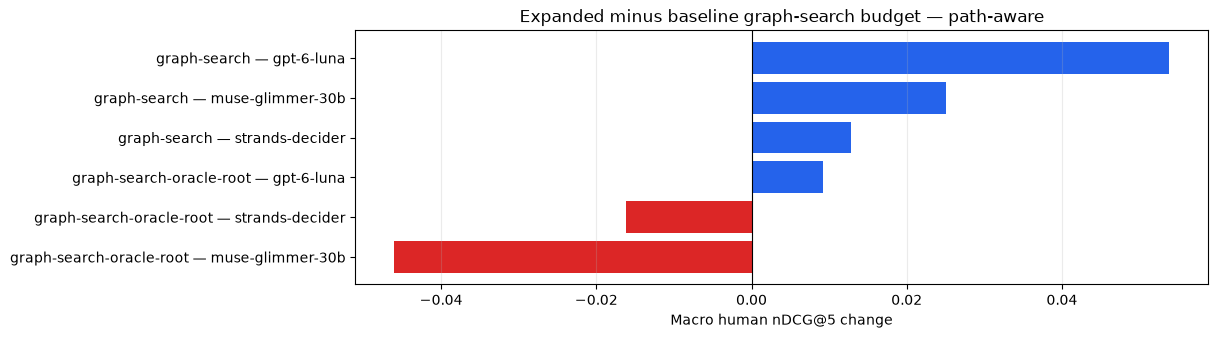

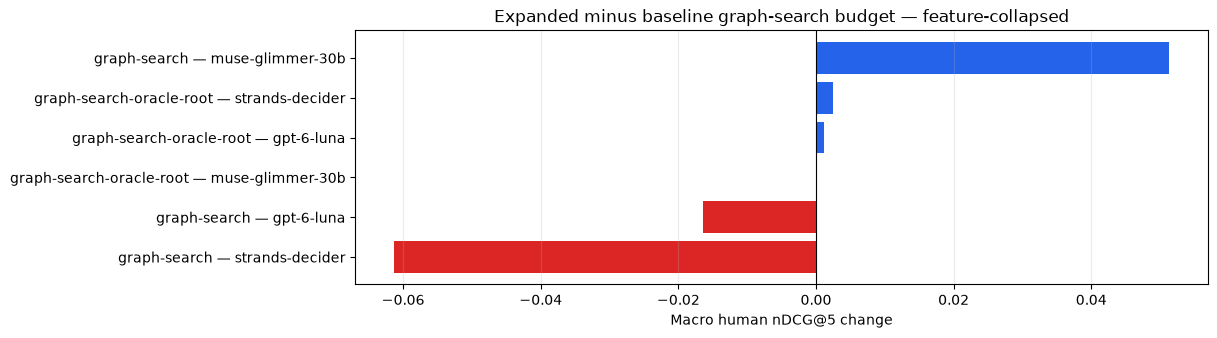

In [3]:
baseline_keys = ['method', 'model', 'catalog']
baseline = overall[overall['budget'].map(lambda budget: budget == BASELINE_BUDGET)].set_index(baseline_keys)[metric_columns]
expanded = overall[overall['budget'].map(lambda budget: budget == EXPANDED_BUDGET)].set_index(baseline_keys)[metric_columns]
budget_delta = baseline.join(expanded, how='inner', lsuffix=' baseline', rsuffix=' expanded')
for metric in metric_columns:
    budget_delta[f'{metric} change'] = budget_delta[f'{metric} expanded'] - budget_delta[f'{metric} baseline']

if budget_delta.empty:
    print(f'No complete baseline/expanded pair found for {BASELINE_BUDGET} and {EXPANDED_BUDGET}.')
else:
    display(budget_delta.reset_index().sort_values(['catalog', 'ndcg@5 change'], ascending=[True, False]).round(3))
    for catalog in ('path-aware', 'feature-collapsed'):
        view = budget_delta.reset_index().query('catalog == @catalog').sort_values('ndcg@5 change')
        if view.empty:
            continue
        labels = [f"{row['method']} — {row['model']}" for _, row in view.iterrows()]
        fig, ax = plt.subplots(figsize=(11, max(3, 0.55 * len(view))))
        colors = ['#2563eb' if value >= 0 else '#dc2626' for value in view['ndcg@5 change']]
        ax.barh(labels, view['ndcg@5 change'], color=colors)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_xlabel('Macro human nDCG@5 change')
        ax.set_title(f'Expanded minus baseline graph-search budget — {catalog}')
        ax.grid(axis='x', alpha=0.25)
        plt.show()


In [4]:
def render_budget_pair(index):
    selected = budget_delta.reset_index().iloc[int(index)]
    mask = (
        graph_metrics['method'].eq(selected['method'])
        & graph_metrics['model'].eq(selected['model'])
        & graph_metrics['catalog'].eq(selected['catalog'])
    )
    before = graph_metrics[mask & graph_metrics['budget'].map(lambda budget: budget == BASELINE_BUDGET)].set_index(['suite', 'condition_id'])
    after = graph_metrics[mask & graph_metrics['budget'].map(lambda budget: budget == EXPANDED_BUDGET)].set_index(['suite', 'condition_id'])
    columns = ['condition', 'ndcg@1', 'ndcg@3', 'ndcg@5', 'returned signals', 'top-5 human grades']
    table = before[columns].join(after[columns], how='inner', lsuffix=' baseline', rsuffix=' expanded')
    for metric in ('ndcg@1', 'ndcg@3', 'ndcg@5'):
        table[f'{metric} change'] = table[f'{metric} expanded'] - table[f'{metric} baseline']
    display(Markdown(f"### {selected['method']} — {selected['model']} — {selected['catalog']}"))
    display(table.reset_index().sort_values(['suite', 'condition_id']).round(3))

if budget_delta.empty:
    pass
elif widgets is None:
    render_budget_pair(0)
else:
    budget_picker = widgets.Dropdown(
        options=[(f"{row['catalog']} | {row['method']} | {row['model']}", index) for index, row in budget_delta.reset_index().iterrows()],
        description='Run pair:', layout=widgets.Layout(width='85%'),
    )
    budget_output = widgets.Output()
    def refresh_budget(change=None):
        with budget_output:
            clear_output(wait=True)
            render_budget_pair(budget_picker.value)
    budget_picker.observe(refresh_budget, names='value')
    display(budget_picker, budget_output)
    refresh_budget()


Dropdown(description='Run pair:', layout=Layout(width='85%'), options=(('feature-collapsed | graph-search | gp…

Output()

## Search-trace and decision-tree browser

Choose one graph-search run and condition. The final signal list, per-decision retained actions, and tree all come from that run's saved `graph_search` trace.


In [5]:
def branch_history(step):
    prefix = '- Prior decisions on this branch: '
    for line in step.get('state_context', '').splitlines():
        if line.startswith(prefix):
            value = line[len(prefix):]
            return [] if value == 'none' else value.split(' | ')
    return []

def short_action(action):
    kind = action.get('kind', 'unknown')
    if kind in {'start', 'traverse'}:
        detail = action.get('target_table', '')
    elif action.get('candidate'):
        candidate = action['candidate']
        detail = candidate.get('attribute_table')
        detail = f"{detail}.{candidate.get('attribute_column')}" if detail else 'relationship path'
    else:
        detail = 'stop branch' if kind == 'stop_branch' else 'stop search'
    probability = action.get('probability')
    suffix = f" (p={probability:.2f})" if isinstance(probability, (int, float)) else ''
    return f'{kind}: {detail}{suffix}'

def plot_decision_tree(row, figsize_width=18):
    steps = row['graph_search'].get('trace', [])
    if not steps:
        print('This run has no saved graph-search trace.')
        return
    root = steps[0]
    child_by_parent_action = {}
    for child in steps[1:]:
        history = branch_history(child)
        if history:
            child_by_parent_action[(child.get('parent_branch_id'), history[-1])] = child

    def used_actions(step):
        actions = step.get('expanded_actions', [])
        chosen = next((a for a in actions if a.get('option') == step.get('model_choice')), None)
        if chosen and chosen.get('kind') == 'stop_search':
            return [chosen]
        return [a for a in actions if a.get('kind') != 'stop_search']

    nodes, edges, seen, cursor = [], [], set(), [0.0]
    def build(step, depth):
        branch = step.get('branch_id')
        key = ('decision', branch if branch is not None else 'root')
        if key in seen:
            y = cursor[0]; cursor[0] += 1
            return {'key': key, 'x': depth, 'y': y, 'children': []}
        seen.add(key)
        node = {'key': key, 'x': depth, 'y': None, 'children': [], 'choice': step.get('model_choice')}
        nodes.append({'key': key, 'x': depth, 'y': None, 'type': 'decision', 'label': f"D{step.get('decision_index')}"})
        for action in used_actions(step):
            child_step = child_by_parent_action.get((branch, action.get('option')))
            if child_step is not None:
                child = build(child_step, depth + 1)
            else:
                child = {'key': ('action', len(nodes), len(edges)), 'x': depth + 1, 'y': cursor[0], 'children': []}
                cursor[0] += 1
                nodes.append({'key': child['key'], 'x': child['x'], 'y': child['y'], 'type': action.get('kind'), 'label': short_action(action)})
            node['children'].append((action, child)); edges.append((node, action, child))
        node['y'] = sum(child['y'] for _, child in node['children']) / len(node['children']) if node['children'] else cursor[0]
        if not node['children']:
            cursor[0] += 1
        next(item for item in nodes if item['key'] == key)['y'] = node['y']
        return node

    build(root, 0)
    fig, ax = plt.subplots(figsize=(figsize_width, max(5, min(30, 0.42 * max(cursor[0], 8)))))
    colors = {'decision': '#e8eef7', 'start': '#cfe8ff', 'traverse': '#cfe8ff', 'select_attribute': '#d9f2d9', 'select_relationship': '#d9f2d9', 'stop_branch': '#eeeeee', 'stop_search': '#ffd9d9'}
    for parent, action, child in edges:
        chosen = action.get('option') == parent.get('choice')
        color = '#228833' if chosen else '#777777'
        ax.plot([parent['x'], child['x']], [parent['y'], child['y']], color=color, linewidth=2 if chosen else 1, alpha=.85, zorder=1)
        ax.text((parent['x'] + child['x']) / 2, (parent['y'] + child['y']) / 2, short_action(action), fontsize=7, ha='left', va='center', color=color, bbox={'facecolor':'white','alpha':.78,'edgecolor':'none','pad':1}, zorder=3)
    for node in nodes:
        if node['type'] == 'decision':
            ax.scatter(node['x'], node['y'], s=520, facecolor=colors['decision'], edgecolor='#333333', zorder=2)
            ax.text(node['x'], node['y'], node['label'], ha='center', va='center', fontsize=8, weight='bold')
        else:
            ax.scatter(node['x'], node['y'], s=55, marker='s', facecolor=colors.get(node['type'], '#eeeeee'), edgecolor='#555555', zorder=2)
            ax.text(node['x']+.08, node['y'], node['label'], ha='left', va='center', fontsize=7)
    ax.set_title(f"{row.get('condition_id')} — {row.get('method')} — {row.get('model')}")
    ax.set_xlabel('Decision depth'); ax.set_yticks([]); ax.grid(axis='x', alpha=.2)
    ax.set_xlim(-.5, max(node['x'] for node in nodes)+1.6); ax.set_ylim(max(node['y'] for node in nodes)+1, min(node['y'] for node in nodes)-1)
    for spine in ('left', 'right', 'top'): ax.spines[spine].set_visible(False)
    plt.show()

by_label = {}
for item in trace_runs:
    by_label.setdefault(item['label'], []).append(item['run'])

def render_trace(label, condition_id):
    row = next(run for run in by_label[label] if run.get('condition_id') == condition_id)
    graph = row['graph_search']
    display(Markdown(f"### {row['condition_id']} — {row['condition']}\n\n**Stop:** {graph.get('stop_reason')} | **Model calls:** {graph.get('model_calls')} | **Signals returned:** {len(row.get('signals', []))}"))
    signals = pd.DataFrame([{
        'kind': signal.get('kind'), 'hops': signal.get('hops'), 'path': ' → '.join(signal.get('path', [])),
        'signal': f"{signal.get('attribute_table')}.{signal.get('attribute_column')}" if signal.get('kind') == 'attribute' else 'relationship path',
        'description': signal.get('description'),
    } for signal in row.get('signals', [])])
    display(signals)
    decisions = []
    for step in graph.get('trace', []):
        selected = next((a for a in step.get('legal_actions', []) if a.get('option') == step.get('model_choice')), None)
        probability = selected.get('probability') if selected else None
        decisions.append({'step': step.get('decision_index'), 'branch': step.get('branch_id') or 'root', 'path': ' → '.join(step.get('current_path') or ()), 'selected action': step.get('model_choice'), 'selected probability': round(probability, 4) if isinstance(probability, (int, float)) else None, 'retained actions': '; '.join(short_action(action) for action in step.get('expanded_actions', []))})
    display(pd.DataFrame(decisions))
    plot_decision_tree(row)

if not by_label:
    print('No saved graph-search traces were found.')
elif widgets is None:
    first_label = next(iter(by_label)); render_trace(first_label, by_label[first_label][0]['condition_id'])
else:
    run_picker = widgets.Dropdown(options=sorted(by_label), description='Run:', layout=widgets.Layout(width='95%'))
    condition_picker = widgets.Dropdown(description='Condition:', layout=widgets.Layout(width='50%'))
    trace_output = widgets.Output()
    def update_conditions(change=None):
        values = [run.get('condition_id') for run in by_label[run_picker.value]]
        condition_picker.options = values
        condition_picker.value = values[0]
    def refresh_trace(change=None):
        with trace_output:
            clear_output(wait=True); render_trace(run_picker.value, condition_picker.value)
    run_picker.observe(update_conditions, names='value')
    condition_picker.observe(refresh_trace, names='value')
    display(widgets.VBox([run_picker, condition_picker, trace_output]))
    update_conditions(); refresh_trace()


## Reading the decision tree

Each circle is one model decision. Its outgoing edges are legal actions retained by bounded search. Green is the action ranked first at that state; gray is an additional branch retained because of `branch_width`. A signal list is the union of signals selected across explored branches, then optionally reranked by the method's final stage.
